In [45]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Visualization & pandas display settings
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

In [46]:
CSV_NAME = "AB_NYC_2019.csv"

if os.path.exists(CSV_NAME):
    csv_path = CSV_NAME
else:
    try:
        import kagglehub
        folder = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")
        csv_path = os.path.join(folder, CSV_NAME)
    except Exception as e:
        print("Automatic download failed:", e)
        print("Please upload AB_NYC_2019.csv manually.")
        from google.colab import files
        uploaded = files.upload()
        csv_path = list(uploaded.keys())[0]

df_raw = pd.read_csv(csv_path)
df = df_raw.copy()  # Keep df_raw untouched for reference
print(f"Loaded successfully from: {csv_path}")
print(f"Dataset Shape: {df.shape}")

Loaded successfully from: AB_NYC_2019.csv
Dataset Shape: (48895, 16)


In [47]:
print("Columns:", list(df.columns))
print("\nData Types:")
print(df.dtypes)

display(df.head())
display(df.describe().T)


missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().sum() / len(df) * 100).round(2)
})
missing = missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False)

print("\nColumns with Missing Data:")
display(missing)

Columns: ['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Data Types:
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


,count,mean,std,min,25%,50%,75%,max
id,48895.0,1.901714e+07,1.098311e+07,2539.00000,9.471945e+06,1.967728e+07,2.915218e+07,3.648724e+07
host_id,48895.0,6.762001e+07,7.861097e+07,2438.00000,7.822033e+06,3.079382e+07,1.074344e+08,2.743213e+08
latitude,48895.0,4.072895e+01,5.453008e-02,40.49979,4.069010e+01,4.072307e+01,4.076311e+01,4.091306e+01
longitude,48895.0,-7.395217e+01,4.615674e-02,-74.24442,-7.398307e+01,-7.395568e+01,-7.393627e+01,-7.371299e+01
price,48895.0,1.527207e+02,2.401542e+02,0.00000,6.900000e+01,1.060000e+02,1.750000e+02,1.000000e+04
minimum_nights,48895.0,7.029962e+00,2.051055e+01,1.00000,1.000000e+00,3.000000e+00,5.000000e+00,1.250000e+03
number_of_reviews,48895.0,2.327447e+01,4.455058e+01,0.00000,1.000000e+00,5.000000e+00,2.400000e+01,6.290000e+02
reviews_per_month,38843.0,1.373221e+00,1.680442e+00,0.01000,1.900000e-01,7.200000e-01,2.020000e+00,5.850000e+01
calculated_host_listings_count,48895.0,7.143982e+00,3.295252e+01,1.00000,1.000000e+00,1.000000e+00,2.000000e+00,3.270000e+02
availability_365,48895.0,1.127813e+02,1.316223e+02,0.00000,0.000000e+00,4.500000e+01,2.270000e+02,3.650000e+02



Columns with Missing Data:


,missing_count,missing_percent
reviews_per_month,10052,20.56
last_review,10052,20.56
host_name,21,0.04
name,16,0.03


In [48]:
print(f"Dataset Shape: {df.shape}")
print("Columns:", list(df.columns))
print("\nData Types:")
print(df.dtypes)
display(df.head())


numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()

print("\nNumerical Columns (Discrete/Continuous):", numerical_cols)
print("Categorical Columns (Nominal/Ordinal):", categorical_cols)


missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().sum() / len(df) * 100).round(2)
})
missing = missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False)

print("\nColumns with Missing Data:")
display(missing)

Dataset Shape: (48895, 16)
Columns: ['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Data Types:
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64
dtype: object


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0



Numerical Columns (Discrete/Continuous): ['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
Categorical Columns (Nominal/Ordinal): ['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']

Columns with Missing Data:


,missing_count,missing_percent
reviews_per_month,10052,20.56
last_review,10052,20.56
host_name,21,0.04
name,16,0.03


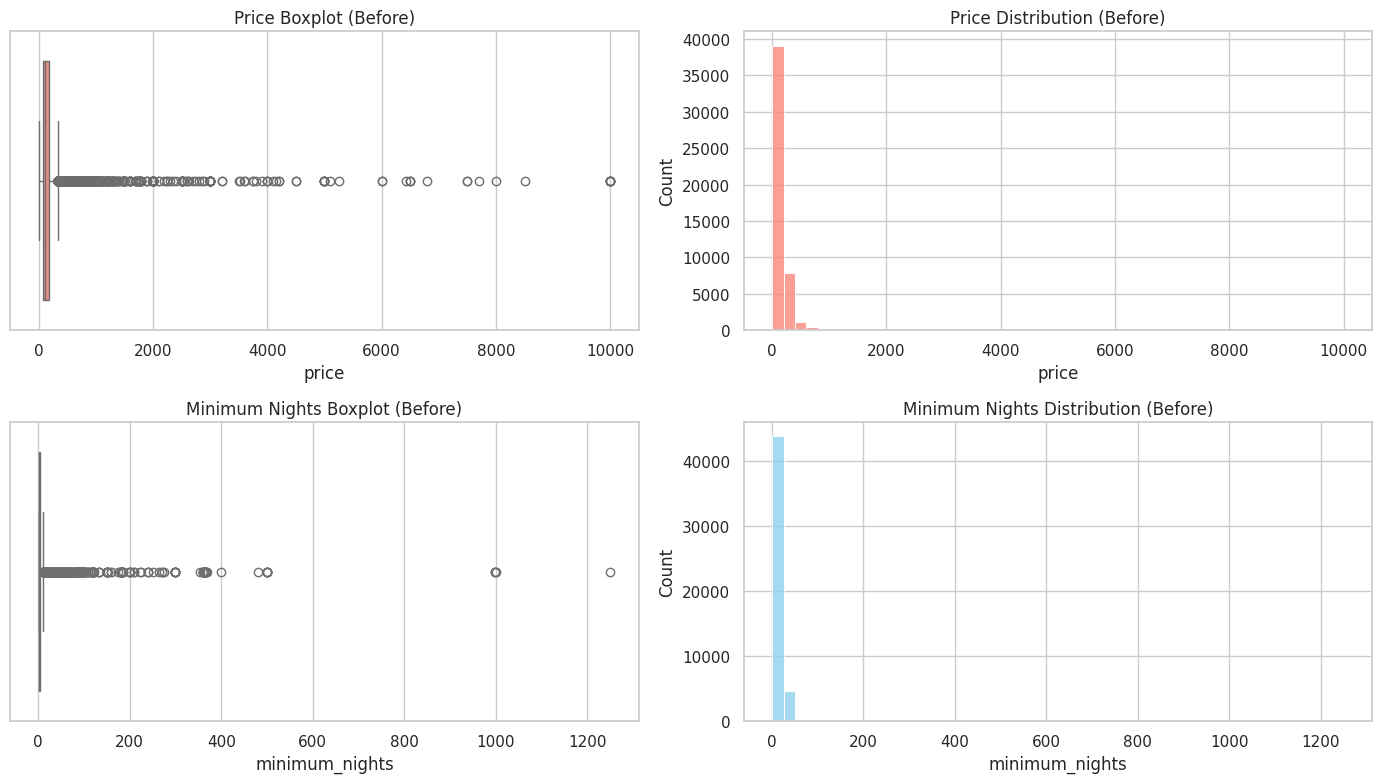

Price 99th percentile cap: $799.00
Rows before: 48,895 | Rows after: 47,692 | Removed: 1,203


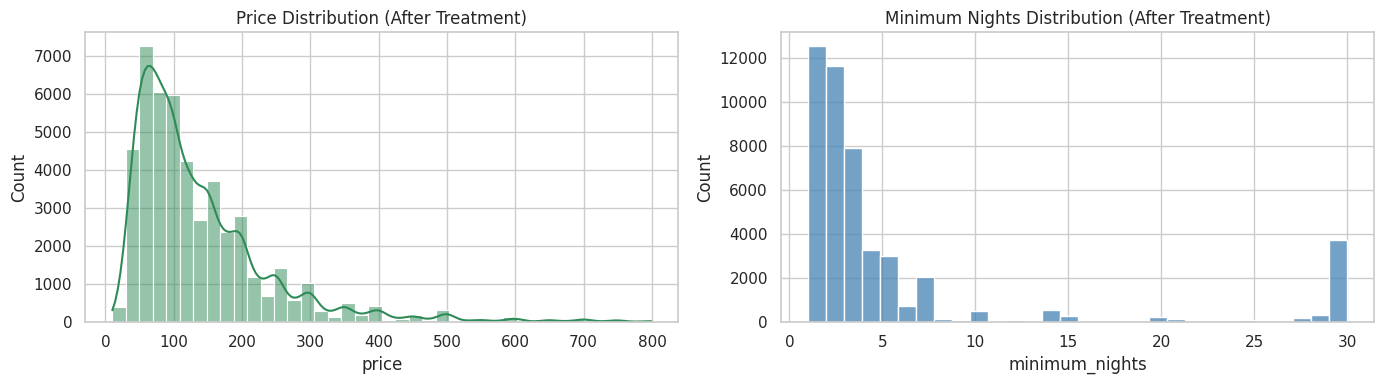

In [49]:

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sns.boxplot(x=df["price"], ax=axes[0, 0], color="salmon")
axes[0, 0].set_title("Price Boxplot (Before)")

sns.histplot(df["price"], bins=50, ax=axes[0, 1], color="salmon")
axes[0, 1].set_title("Price Distribution (Before)")

sns.boxplot(x=df["minimum_nights"], ax=axes[1, 0], color="skyblue")
axes[1, 0].set_title("Minimum Nights Boxplot (Before)")

sns.histplot(df["minimum_nights"], bins=50, ax=axes[1, 1], color="skyblue")
axes[1, 1].set_title("Minimum Nights Distribution (Before)")

plt.tight_layout()
plt.show()


price_cap = df["price"].quantile(0.99)
before_rows = len(df)

df = df[(df["price"] > 0) & (df["price"] <= price_cap)]
df = df[df["minimum_nights"] <= 30]

after_rows = len(df)
print(f"Price 99th percentile cap: ${price_cap:.2f}")
print(f"Rows before: {before_rows:,} | Rows after: {after_rows:,} | Removed: {before_rows - after_rows:,}")


fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df["price"], bins=40, kde=True, ax=axes[0], color="seagreen")
axes[0].set_title("Price Distribution (After Treatment)")

sns.histplot(df["minimum_nights"], bins=30, ax=axes[1], color="steelblue")
axes[1].set_title("Minimum Nights Distribution (After Treatment)")

plt.tight_layout()
plt.show()

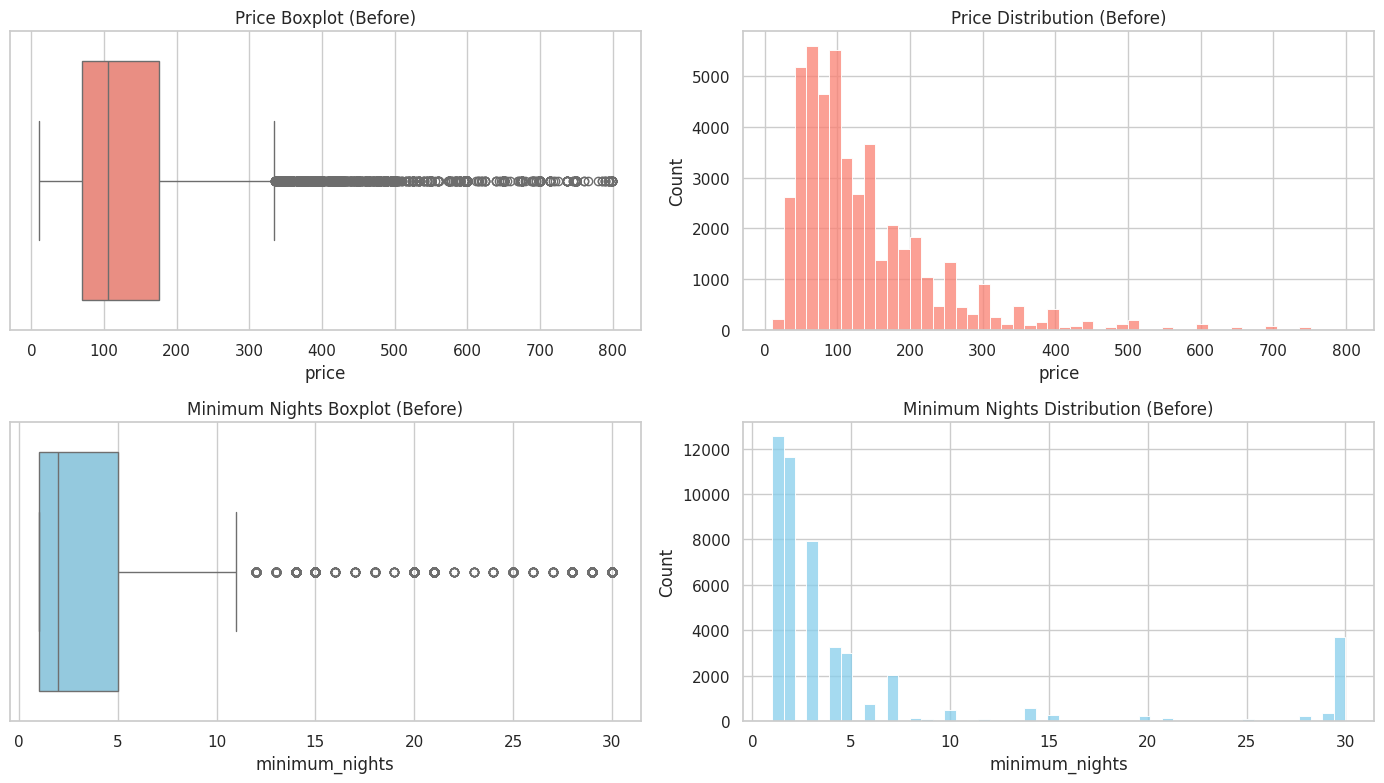

Price 95th percentile cap: $345.45
Minimum Nights 95th percentile cap: 30 nights
Rows before: 47,692 | Rows after: 45,307 | Removed: 2,385


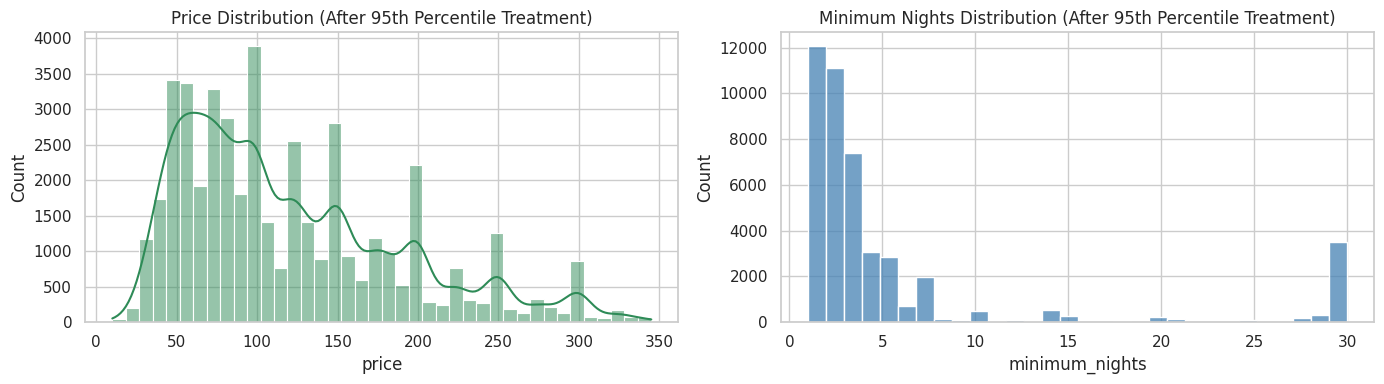

In [50]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sns.boxplot(x=df["price"], ax=axes[0, 0], color="salmon")
axes[0, 0].set_title("Price Boxplot (Before)")

sns.histplot(df["price"], bins=50, ax=axes[0, 1], color="salmon")
axes[0, 1].set_title("Price Distribution (Before)")

sns.boxplot(x=df["minimum_nights"], ax=axes[1, 0], color="skyblue")
axes[1, 0].set_title("Minimum Nights Boxplot (Before)")

sns.histplot(df["minimum_nights"], bins=50, ax=axes[1, 1], color="skyblue")
axes[1, 1].set_title("Minimum Nights Distribution (Before)")

plt.tight_layout()
plt.show()


price_95 = df["price"].quantile(0.95)
nights_95 = df["minimum_nights"].quantile(0.95)
before_rows = len(df)

df = df[(df["price"] > 0) & (df["price"] <= price_95)]
df = df[df["minimum_nights"] <= nights_95]

after_rows = len(df)
print(f"Price 95th percentile cap: ${price_95:.2f}")
print(f"Minimum Nights 95th percentile cap: {nights_95:.0f} nights")
print(f"Rows before: {before_rows:,} | Rows after: {after_rows:,} | Removed: {before_rows - after_rows:,}")


fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df["price"], bins=40, kde=True, ax=axes[0], color="seagreen")
axes[0].set_title("Price Distribution (After 95th Percentile Treatment)")

sns.histplot(df["minimum_nights"], bins=30, ax=axes[1], color="steelblue")
axes[1].set_title("Minimum Nights Distribution (After 95th Percentile Treatment)")

plt.tight_layout()
plt.show()

In [51]:
X = df_encoded.drop(columns=["price"])
y = df_encoded["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Training set: {X_train.shape[0]:,} rows, {X_train.shape[1]} features")
print(f"Testing set : {X_test.shape[0]:,} rows, {X_test.shape[1]} features")

Training set: 38,153 rows, 13 features
Testing set : 9,539 rows, 13 features


In [52]:
model = LinearRegression()
model.fit(X_train, y_train)


y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)
mae_test = mean_absolute_error(y_test, y_test_pred)
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))

print("=== Linear Regression Performance ===")
print(f"Train R² : {r2_train:.4f}")
print(f"Test  R² : {r2_test:.4f}")
print(f"Test MAE : ${mae_test:.2f}")
print(f"Test RMSE: ${rmse_test:.2f}")

=== Linear Regression Performance ===
Train R² : 0.3672
Test  R² : 0.3632
Test MAE : $52.76
Test RMSE: $83.91


In [53]:
model = LinearRegression()
model.fit(X_train, y_train)


y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)


r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)
mae_test = mean_absolute_error(y_test, y_test_pred)
mse_test = mean_squared_error(y_test, y_test_pred)
rmse_test = np.sqrt(mse_test)

print("=== Linear Regression Performance ===")
print(f"Train R² : {r2_train:.4f}")
print(f"Test  R² : {r2_test:.4f}")
print(f"Test MAE : ${mae_test:.2f}")
print(f"Test MSE : {mse_test:.2f}")
print(f"Test RMSE: ${rmse_test:.2f}")

=== Linear Regression Performance ===
Train R² : 0.3672
Test  R² : 0.3632
Test MAE : $52.76
Test MSE : 7040.78
Test RMSE: $83.91


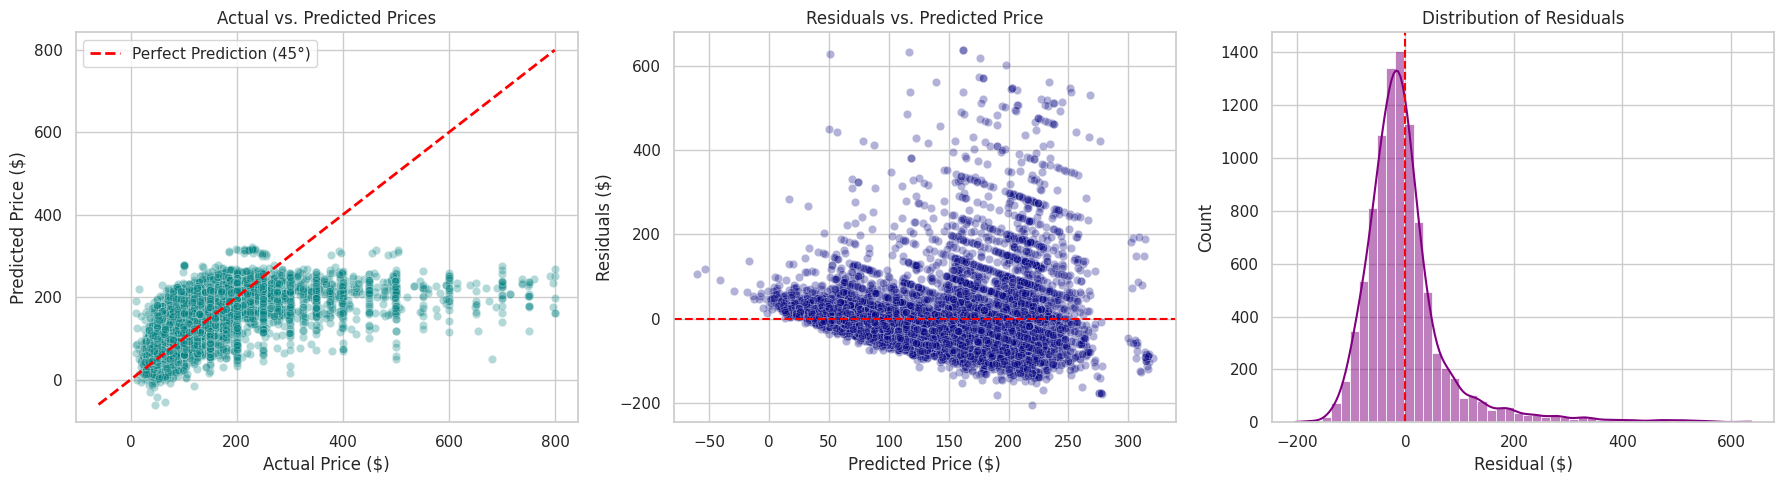

Task 7.3 Insight: The model performs significantly better on cheap-to-mid-range listings.
For higher-priced listings, actual prices sit well above the 45° diagonal line (underprediction),
because luxury amenities, interior quality, and exact street-level desirability are not captured in the dataset.


In [44]:
residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))


sns.scatterplot(x=y_test, y=y_test_pred, alpha=0.3, ax=axes[0], color="teal")
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())
axes[0].plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=2, label="Perfect Prediction (45°)")
axes[0].set_title("Actual vs. Predicted Prices")
axes[0].set_xlabel("Actual Price ($)")
axes[0].set_ylabel("Predicted Price ($)")
axes[0].legend()


sns.scatterplot(x=y_test_pred, y=residuals, alpha=0.3, ax=axes[1], color="navy")
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals vs. Predicted Price")
axes[1].set_xlabel("Predicted Price ($)")
axes[1].set_ylabel("Residuals ($)")


sns.histplot(residuals, bins=50, kde=True, ax=axes[2], color="purple")
axes[2].axvline(0, color="red", linestyle="--")
axes[2].set_title("Distribution of Residuals")
axes[2].set_xlabel("Residual ($)")

plt.tight_layout()
plt.show()

print("Task 7.3 Insight: The model performs significantly better on cheap-to-mid-range listings.")
print("For higher-priced listings, actual prices sit well above the 45° diagonal line (underprediction),")
print("because luxury amenities, interior quality, and exact street-level desirability are not captured in the dataset.")